# Lista de Exercícios 02

## Interpolação Polinomial: polinômios de Lagrange, métodfo de Newton

Em sala de aula estudamos os polinômios interpoladores de Lagrange com base no seguinte teorema:

Suponha que $x_0, x_1, \dots, x_n$ sejam números distíntos noo interval $[a, b]$ e $f\in C^{n+1}[a,b]$. Então, para cada $x\in[a,b]$ existe um número $\xi(x)$ (geralmente desconhecido) entre $x_0, x_1, \dots, x_n$ eportanto em $(a,b)$, tal que:

$$ 
f(x) = P_n(x) + \frac{f^{n+1}(\xi(x))}{(n+1)!}(x-x_0)(x-x_1)\dots(x-x_n)  
$$

A forma de Lagrange é dada por

$$
P_n(x)=\sum_{i=0}^{n} y_i L_i(x),
$$

onde

$$
L_i(x)=\prod_{j=0, j\ne i}^{n} \frac{x-x_j}{x_i-x_j}.
$$

Cada polinômio básico $(L_i(x))$:
- vale 1 em $(x_i)$;
- vale 0 nos demais pontos.

In [1]:
import numpy as np
import matplotlib.pyplot as plt
import math

In [2]:
def lagrange_basis(x, xs, i):
    L = 1.0
    for j in range(len(xs)):
        if j != i:
            L *= (x - xs[j]) / (xs[i] - xs[j])
    return L

def lagrange_interp(x, xs, ys):
    total = 0.0
    for i in range(len(xs)):
        total += ys[i] * lagrange_basis(x, xs, i)
    return total

---

__Exercicio 1__ Suponha que você precise construir tabelas com oito casas decimais para a função logaritmo comum, ou de base 10, de x = 1 a x = 10, de forma que a interpolação __linear__ tenha uma precisão de 10⁻⁶. Determine um limite para o tamanho do passo dessa tabela. Qual seria o valor do tamanho do passo que você escolheria para garantir que x = 10 esteja incluído na tabela?




**1. Fórmula do Erro**

Para $n=1$, a fórmula do erro de Lagrange é:
$$|E(x)| = \left| \frac{f''(\xi)}{2!} (x-x_0)(x-x_1) \right|$$

$|(x-x_0)(x-x_1)|$ é maximizado no ponto médio do intervalo $[x_0, x_1]$, resultando em $h^2/4$. Assim, o limite superior do erro é dado por:
$$|E(x)| \le \frac{M_2 \cdot h^2}{8}$$
Onde $M_2 = \max |f''(x)|$ no intervalo $[1, 10]$.

**2. Cálculo de $M_2$**

$f(x) = \log_{10}(x) = \frac{\ln(x)}{\ln(10)}$:
1. **Primeira derivada:** $f'(x) = \frac{1}{x \ln(10)}$
2. **Segunda derivada:** $f''(x) = -\frac{1}{x^2 \ln(10)}$

O valor absoluto de $f''(x)$ é máximo quando $x$ é mínimo. No intervalo $[1, 10]$, isso ocorre em $x=1$:
$$M_2 = \left| f''(1) \right| = \frac{1}{\ln(10)} \approx 0.434294$$

**3. Determinando o Passo $h$**

Queremos $|E(x)| \le 10^{-6}$:
$$\frac{0.434294 \cdot h^2}{8} \le 10^{-6}$$
$$h^2 \le \frac{8 \cdot 10^{-6}}{0.434294} \approx 18.42068 \times 10^{-6}$$
$$h \le \sqrt{18.42068 \times 10^{-6}} \approx 0.0042919$$

**4. Escolha Prática do Passo**

Para incluir $x=10$ exatamente, o número de intervalos $N = \frac{10-1}{h}$ deve ser inteiro.
- Se $h = 0.0042919$, temos $N \approx 2096.97$.
- Arredondamos para baixo $h = 0.004$:
- $N = \frac{9}{0.004} = 2250$.

**Conclusão:** O tamanho do passo escolhido é **$h = 0.004$**, garantindo o erro abaixo de $10^{-6}$ e a inclusão de $x=10$.

---

__Exercicio 2__. Seja $f(x) = e^x$, para $0 \leq x \leq 2$.

a. Aproxime $f(0{,}25)$ usando interpolação linear com $x_0 = 0$ e $x_1 = 0{,}5$.

b. Aproxime $f(0{,}75)$ usando interpolação linear com $x_0 = 0{,}5$ e $x_1 = 1$.

c. Aproxime $f(0{,}25)$ e $f(0{,}75)$ usando o segundo polinômio interpolador com $x_0 = 0, x_1 = 1$ e $x_2 = 2$.

d. Quais aproximações são melhores e por quê?

In [ ]:

def f(x):
    return math.exp(x) 

exato_25 = f(0.25)
exato_75 = f(0.75)

print(f"Valores Exatos:")
print(f"f(0.25) = {exato_25:.6f}")
print(f"f(0.75) = {exato_75:.6f}\n")

# --- a. | x = 0.25 ---
xs_a = [0.0, 0.5]
ys_a = [f(x) for x in xs_a]
aprox_a = lagrange_interp(0.25, xs_a, ys_a)
erro_a = abs(exato_25 - aprox_a)

print("a. Interpolação Linear:")
print(f"Aproximação f(0.25): {aprox_a:.6f} | Erro: {erro_a:.6f}\n")

# --- b. | x = 0.75 ---
xs_b = [0.5, 1.0]
ys_b = [f(x) for x in xs_b]
aprox_b = lagrange_interp(0.75, xs_b, ys_b)
erro_b = abs(exato_75 - aprox_b)

print("b. Interpolação Linear:")
print(f"Aproximação f(0.75): {aprox_b:.6f} | Erro: {erro_b:.6f}\n")

# --- c. | x = 0.25 e 0.75 ---
xs_c = [0.0, 1.0, 2.0]
ys_c = [f(x) for x in xs_c]
aprox_c_25 = lagrange_interp(0.25, xs_c, ys_c)
erro_c_25 = abs(exato_25 - aprox_c_25)

aprox_c_75 = lagrange_interp(0.75, xs_c, ys_c)
erro_c_75 = abs(exato_75 - aprox_c_75)

print("c. Interpolação Quadrática:")
print(f"Aproximação f(0.25): {aprox_c_25:.6f} | Erro: {erro_c_25:.6f}")
print(f"Aproximação f(0.75): {aprox_c_75:.6f} | Erro: {erro_c_75:.6f}")

Valores Exatos:
f(0.25) = 1.284025
f(0.75) = 2.117000

a. Interpolação Linear:
Aproximação f(0.25): 1.324361 | Erro: 0.040335

b. Interpolação Linear:
Aproximação f(0.75): 2.183502 | Erro: 0.066502

c. Interpolação Quadrática:
Aproximação f(0.25): 1.152774 | Erro: 0.131251
Aproximação f(0.75): 2.011915 | Erro: 0.105085


As aproximações dos itens a e b foram melhores. Isso ocorreu devido ao menor espaçamento entre os pontos utilizados. Enquanto em a e b os pontos estão distanciados em $0{,}5$ um do outro, em c essa distância é de $1{,}0$. Esse espaçamento impacta diretamente a fórmula do erro, já que a distância entre os nós de interpolação é um dos principais fatores que determinam a precisão do método.

---

## Método de Neville

Uma dificuldade prática com a interpolação de Lagrange é que o termo de erro é difícil de aplicar, de modo que o grau do polinômio necessário para a precisão desejada geralmente não é conhecido até que os cálculos sejam realizados. Uma prática comum é calcular os resultados obtidos com vários polinômios até que se obtenha uma concordância adequada. No entanto, o trabalho realizado no cálculo da aproximação pelo segundo polinômio não diminui o trabalho necessário para calcular a terceira aproximação; tampouco a quarta aproximação é mais fácil de obter depois que a terceira aproximação é conhecida, e assim por diante. Agora, vamos derivar esses polinômios de aproximação de uma maneira que utilize os cálculos anteriores de forma mais vantajosa.

__Definição__ : Seja $f$ uma função definida em $x_0, x_1, x_2, \dots, x_n$, e suponha que $m_1, m_2, \dots, m_k$ sejam $k$ inteiros distintos, com $0 \leq m_i \leq n$ para cada $i$. O polinômio de Lagrange que coincide com $f(x)$ nos $k$ pontos $x_{m_1} , x_{m_2} , \dots , x_{m_k}$ é denotado por $P_{m_1,m_2,\dots,m_k}(x)$.

O próximo resultado descreve um método para gerar aproximações de polinômios de Lagrange recursivamente.

__Teprema__: Seja $f$ definida em $x_0, x_1, \dots, x_k$, e sejam $x_j$ e $x_i$ dois números distintos neste conjunto. Então

$$ P(x) = \frac{(x-x_j)P_{0,1,\dots,j-1,j+1,\dots,k}(x) - (x-x_i)P_{0,1,\dots,i-1,i+1,\dots,k}(x)}{x_i-x_j} $$

é o $k$-ésimo polinômio de Lagrange que interpola $f$ nos $k + 1$ pontos $x_0, x_1, \dots, x_k$.

---

__Exercício 3__. Veja o psudocódigo a seguir e construa uma função que implemente o método iterativo de Neville para interpolação por polinômios de Lagrange. Utilize como exemplo os valores fornecidos no arqivo Table-3_2.csv para estimar o valor de $x=1{,}5$. A função que se deseja aproximar é, na verdade, a função de _Bessel_ de primeira espécie de ordem zero, cujo valor em $1{,}5$ é conhecido como $0{,}5118277$. Veja no  exemplo como carregar estes dados do arquivo.  

In [4]:
"""
Neville’s Iterated Interpolation
To evaluate the interpolating polynomial P on the n + 1 distinct numbers x0, ..., xn at the
number x for the function f:
INPUT: 
    numbers x, x0 , x1 , ..., xn; 
    values f(x0), f(x1), ..., f(xn) as the first column Q0,0 ,Q1,0, ..., Qn,0 of Q.
OUTPUT: the table Q with P(x) = Qn,n.
Step 1. for 1 = 1 to n do
            for j = 1 to i do
                Qi,j = (x - xi-j)Qi,j-1 - (x - xi)Qi-1,j-1 /(xi - xi-j)
Step 2. return Q

O algoritmo deve ser modificado para permitir a adição de novos nós de interpolação. Por exemplo, 
a desigualdade

|Qi,i - Qi-1,i-1| < ε

pode ser usada como critério de parada, onde ε é uma tolerância de erro predefinida. 
Se a desigualdade for verdadeira, Qi,i é uma aproximação razoável de f(x). Se a desigualdade 
for falsa, um novo ponto de interpolação, xi+1, é adicionado.
"""
def neville_interpolation(x, x_values, f_values, epsilon):
    n = len(x_values)
    Q = np.zeros((n, n))
    
    Q[:, 0] = f_values
        
    for i in range(1, n):
        for j in range(1, i + 1):
            termo1 = (x - x_values[i - j]) * Q[i, j - 1]
            termo2 = (x - x_values[i]) * Q[i - 1, j - 1]
            Q[i, j] = (termo1 - termo2) / (x_values[i] - x_values[i - j])
            
        if abs(Q[i, i] - Q[i - 1, i - 1]) < epsilon:
            return Q   
        
    return Q

In [5]:
import numpy as np
import matplotlib.pyplot as plt
import pandas as pd
from IPython.display import display

In [6]:
# Exemplo 1. Importar a tabela como um dataframe do arquivo Table-3_2.csv
df = pd.read_csv('Table-3_2.csv')
display(df)

,x,f(x)
0,1.0,0.765198
1,1.3,0.620086
2,1.6,0.455402
3,1.9,0.281819
4,2.2,0.110362


In [7]:
x_i = df['x'].values
y_i = df['f(x)'].values
x = 1.5
y = 0.5118277

In [25]:
n = len(y_i)

Q = neville_interpolation(x, x_i, y_i, 1e-5)
y_aprox = Q[n-1, n-1]

print(f"Ponto estimado por Neville: {y_aprox} | Erro absoluto: {abs(y - y_aprox)}")

Ponto estimado por Neville: 0.5118199942386831 | Erro absoluto: 7.70576131692291e-06


In [27]:
import pprint
pprint.pprint(Q)

array([[0.7651977 , 0.        , 0.        , 0.        , 0.        ],
       [0.620086  , 0.52334487, 0.        , 0.        , 0.        ],
       [0.4554022 , 0.5102968 , 0.51247148, 0.        , 0.        ],
       [0.2818186 , 0.5132634 , 0.51128567, 0.51181269, 0.        ],
       [0.1103623 , 0.510427  , 0.51373613, 0.51183021, 0.51181999]])


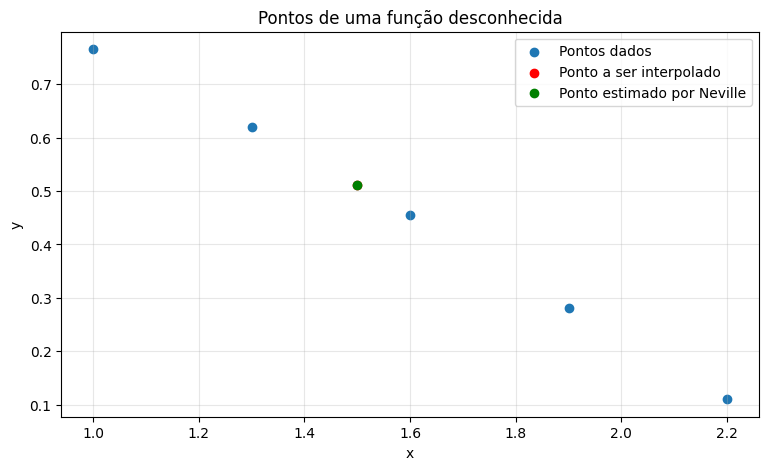

In [9]:
plt.figure(figsize=(9,5))
plt.scatter(x_i, y_i, label="Pontos dados")
plt.scatter(x, y, color='red', label="Ponto a ser interpolado")
plt.scatter(x, y_aprox, color='green', label="Ponto estimado por Neville")
plt.grid(True, alpha=0.3)
plt.xlabel("x")
plt.ylabel("y")
plt.title("Pontos de uma função desconhecida")
plt.legend()
plt.show()

---

__Exercício 4__. Use o método de Neville, implementado anteriormente, para aproximar $\sqrt{3}$ com as seguintes funções e valores.

a. $f(x) = 3^x$ e os valores $x_0 = −2, x_1 = −1, x_2 = 0, x_3 = 1 \,\,\text{e}\,\, x_4 = 2.$

b. $f(x) = \sqrt{x}$ e os valores $x_0 = 0, x_1 = 1, x_2 = 2, x_3 = 4 \,\,\text{e}\,\, x_4 = 5$.

c. Compare a precisão da aproximação de (a) e (b). 

In [10]:
epsilon = 1e-5

# ------------ a. ------------
def f(x):
    return 3**x

X = 0.5
y_real = f(X)

xs = [-2, -1, 0, 1, 2]
ys = [f(x) for x in xs]

n = len(ys)
Q = neville_interpolation(X, xs, ys, epsilon)
y_aprox_a = Q[n-1, n-1]

print("----------- a. -----------")
print(f"Valor real: {y_real}")
print(f"Valor aproximado por Neville: {y_aprox_a}")
print(f"Erro absoluto: {abs(y_real - y_aprox_a)}")

# ------------ b. ------------

def f(x):
    return math.sqrt(x)

X = 3
y_real = f(X)

xs = [0, 1, 2, 4, 5]
ys = [f(x) for x in xs]

n = len(ys)
Q = neville_interpolation(X, xs, ys, epsilon)
y_aprox_b = Q[n-1, n-1]

print("\n----------- b. -----------")
print(f"Valor real: {y_real}")
print(f"Valor aproximado por Neville: {y_aprox_b}")
print(f"Erro absoluto: {abs(y_real - y_aprox_b)}")



----------- a. -----------
Valor real: 1.7320508075688772
Valor aproximado por Neville: 1.7083333333333335
Erro absoluto: 0.023717474235543712

----------- b. -----------
Valor real: 1.7320508075688772
Valor aproximado por Neville: 1.6906067646231164
Erro absoluto: 0.04144404294576076


A aproximação **(a)** é mais precisa. Isso ocorre porque a função $f(x) = 3^x$ é suave e possui derivadas bem-comportadas em todo o intervalo. Já a função $f(x) = \sqrt{x}$ do item **(b)** possui derivadas que tendem ao infinito quando $x$ se aproxima de zero. Como o zero é um dos nós utilizados na interpolação do item (b) ($x_0 = 0$), isso faz com que o erro do polinômio cresça.

---

__Exercício 5__. Construa uma sequência de valores de interpolação $y_n$ para $f(1+\sqrt{10})$, onde $f(x)=(1+x^2)^{-1}$ para $-5 \leq x \leq 5$, da seguinte forma: Para cada $n=1,2,\dots, 10$, seja $h=10/n$ y $y_n=P_n(1+\sqrt{10})$, onde $P_n(x)$ é o polinômio interpolador de $f(x)$ nos pontos $x_0^{(n)}, x_1^{(n)}, \dots, x_n^{(n)}$ e $x_j^{(n)}= -5 + jh$, para cada $j=0,1,2,\dots, n$. A sequência ${y_n}$ parece convergir para $f(1 + \sqrt{10})$?  

In [11]:
def f(x):
    return 1 / (1 + x**2)

x_alvo = 1 + np.sqrt(10)
valor_exato = f(x_alvo)

print(f"Valor Exato: {valor_exato:.7f}\n")
print(" n |      y_n      |      Erro     ")
print("-----------------------------------")

for n in range(1, 11):
    x_nos = np.linspace(-5, 5, n + 1)
    y_nos = f(x_nos)
    
    y_n = lagrange_interp(x_alvo, x_nos, y_nos)
    erro = abs(valor_exato - y_n)
    
    print(f"{n:2d} | {y_n:13.7f} | {erro:13.7f}")

Valor Exato: 0.0545716

 n |      y_n      |      Erro     
-----------------------------------
 1 |     0.0384615 |     0.0161100
 2 |     0.3336709 |     0.2790994
 3 |     0.1166052 |     0.0620336
 4 |    -0.3717596 |     0.4263312
 5 |    -0.0548919 |     0.1094635
 6 |     0.6059346 |     0.5513630
 7 |     0.1902492 |     0.1356776
 8 |    -0.5133526 |     0.5679242
 9 |    -0.0668173 |     0.1213889
10 |     0.4483348 |     0.3937632


À medida que o grau $n$ do polinômio aumenta, o erro da aproximação cresce em vez de diminuir. Isso ocorre devido ao **Fenômeno de Runge**, que demonstra que a interpolação de funções como $f(x) = (1+x^2)^{-1}$ usando polinômios de grau elevado com **nós igualmente espaçados** gera oscilações violentas nas extremidades do intervalo $[-5, 5]$. 

Como o ponto avaliado $x = 1 + \sqrt{10} \approx 4{,}162$ está muito próximo da borda do intervalo, ele sofre o impacto dessas instabilidades, fazendo com que a sequência divirja em vez de se aproximar do valor real.

---

__Exercício 6__.  Veja o psudocódigo a seguir e compare com a implementação apresentada em sala de aula . Construa uma função que implemente o método de Diferenças Divididas para interpolação por polinômios de Lagrange. Utilize como exemplo os valores fornecidos no arqivo Table-3_2.csv para estimar o valor de $x=1{,}5$. A função que se deseja aproximar é, na verdade, a função de _Bessel_ de primeira espécie de ordem zero, cujo valor em $1{,}5$ é conhecido como $0{,}5118277$.  

In [12]:
"""
Newton’s Divided-Difference Formula
To obtain the divided-difference coefficients of the interpolatory polynomial P on the (n+1)
distinct numbers x0 , x1 , . . . , xn for the function f:
INPUT numbers x0 , x1 , . . . , xn ; values f (x0 ), f (x1 ), . . . , f (xn ) as 
F0,0 , F1,0 , . . . , Fn,0 .
OUTPUT the numbers F0,0 , F1,1 , . . . , Fn,n as the divided-difference coefficients of P.
Step 1. for j = 1 to n do
            for i = j to n do
                Fi,j = (xi - xi-j)Fi,j-1 - (xi - xi-j)Fi-1,j-1 /(xi - xi-j)
Step 2. return F0,0 , F1,1 , . . . , Fn,n
"""

'\nNewton’s Divided-Difference Formula\nTo obtain the divided-difference coefficients of the interpolatory polynomial P on the (n+1)\ndistinct numbers x0 , x1 , . . . , xn for the function f:\nINPUT numbers x0 , x1 , . . . , xn ; values f (x0 ), f (x1 ), . . . , f (xn ) as \nF0,0 , F1,0 , . . . , Fn,0 .\nOUTPUT the numbers F0,0 , F1,1 , . . . , Fn,n as the divided-difference coefficients of P.\nStep 1. for j = 1 to n do\n            for i = j to n do\n                Fi,j = (xi - xi-j)Fi,j-1 - (xi - xi-j)Fi-1,j-1 /(xi - xi-j)\nStep 2. return F0,0 , F1,1 , . . . , Fn,n\n'

In [13]:
def newton_divided_differences(xs, ys):
    n = len(xs)
    F = np.zeros((n, n))
    
    F[:, 0] = ys
    
    for j in range(1, n):
        for i in range(j, n):
            F[i, j] = (F[i, j-1] - F[i-1, j-1]) / (xs[i] - xs[i-j])
            
    coefficients = np.diag(F)
    return coefficients

In [14]:
def newton_interp(x, xs, coef):
    result = coef[0]
    term = 1.0
    for i in range(1, len(xs)):
        term *= (x - xs[i-1])
        result += coef[i] * term
    return result

In [15]:
x_i = df['x'].values
y_i = df['f(x)'].values
x = 1.5
y = 0.5118277

In [16]:
n = len(y_i)

coef = newton_divided_differences(x_i, y_i)
y_aprox = newton_interp(x, x_i, coef)

print(f"Ponto estimado por newton: {y_aprox} | Erro absoluto: {abs(y - y_aprox)}")

Ponto estimado por newton: 0.5118199942386833 | Erro absoluto: 7.705761316700865e-06


In [28]:
pprint.pprint(coef)

array([ 0.7651977 , -0.48370567, -0.10873389,  0.0658784 ,  0.0018251 ])


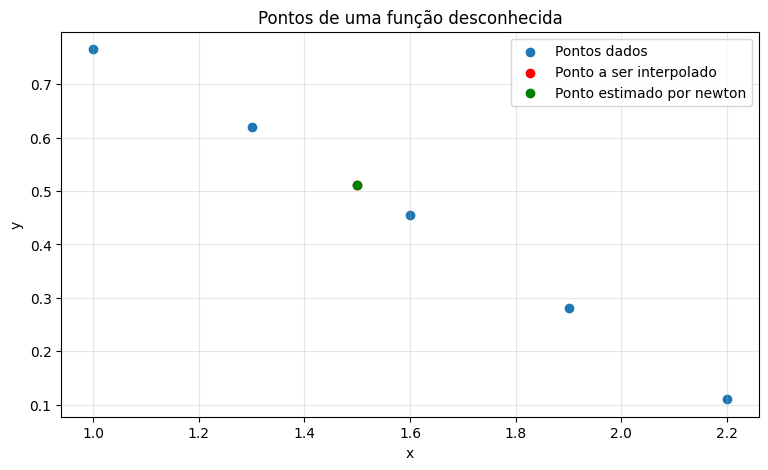

In [17]:
plt.figure(figsize=(9,5))
plt.scatter(x_i, y_i, label="Pontos dados")
plt.scatter(x, y, color='red', label="Ponto a ser interpolado")
plt.scatter(x, y_aprox, color='green', label="Ponto estimado por newton")
plt.grid(True, alpha=0.3)
plt.xlabel("x")
plt.ylabel("y")
plt.title("Pontos de uma função desconhecida")
plt.legend()
plt.show()



* **Código atual:** Constrói uma matriz triangular inferior. Os coeficientes que formam o polinômio de Newton ficam armazenados na **diagonal principal**.
* **Código da sala de aula:** Calcula as diferenças "para frente". Os coeficientes ficam armazenados na **primeira linha** da matriz.

---

__Exrcício 7__. Utilize a fórmula de diferenças de Newton para construir polinômios interpoladores de grau um, dois e três para os dados a seguir. Aproxime o valor especificado utilizando cada um dos polinômios.

a. $f(0{,}43) \,\, \text{se}\,\, f(0)=1, f(0{,}25)=1{,}64872, f(0{,}5)=2{,}71828, f(0{,}75)=4.48169$

b. $f(0{,}25) \,\, \text{se}\,\, f(−1)=0{,}86199480, f(−0{,}5)=0{,}95802009, f(0)=1{,}0986123, f(0{,}5)=
1{,}2943767$

In [18]:
def resolver(item, x_alvo, xs, ys):
    print(f"--- Questão {item}: f({x_alvo}) ---")
    
    coefs_totais = newton_divided_differences(xs, ys)

    p1 = newton_interp(x_alvo, xs[:2], coefs_totais[:2])
    print(f"Grau 1 (P1): {p1:.7f}")

    p2 = newton_interp(x_alvo, xs[:3], coefs_totais[:3])
    print(f"Grau 2 (P2): {p2:.7f}")
    
    p3 = newton_interp(x_alvo, xs[:4], coefs_totais[:4])
    print(f"Grau 3 (P3): {p3:.7f}\n")

# a.
xs_a = np.array([0.0, 0.25, 0.5, 0.75])
ys_a = np.array([1.0, 1.64872, 2.71828, 4.48169])
resolver("a", 0.43, xs_a, ys_a)

# b.
xs_b = np.array([-1.0, -0.5, 0.0, 0.5])
ys_b = np.array([0.86199480, 0.95802009, 1.0986123, 1.2943767])
resolver("b", 0.25, xs_b, ys_b)


--- Questão a: f(0.43) ---
Grau 1 (P1): 2.1157984
Grau 2 (P2): 2.3763825
Grau 3 (P3): 2.3606047

--- Questão b: f(0.25) ---
Grau 1 (P1): 1.1020580
Grau 2 (P2): 1.1856210
Grau 3 (P3): 1.1889351



---

__Exercício 8__. Um censo da população dos Estados Unidos é realizado a cada 10 anos. A tabela a seguir lista a população, em milhares de pessoas, de 1950 a 2000. Os dados também estão representados na figura.

In [19]:
# Importar a tabela como um dataframe do arquivo population.csv
df = pd.read_csv('population.csv')
display(df)

,Year,Population
0,1950,151326
1,1960,179323
2,1970,203302
3,1980,226542
4,1990,249633
5,2000,281422


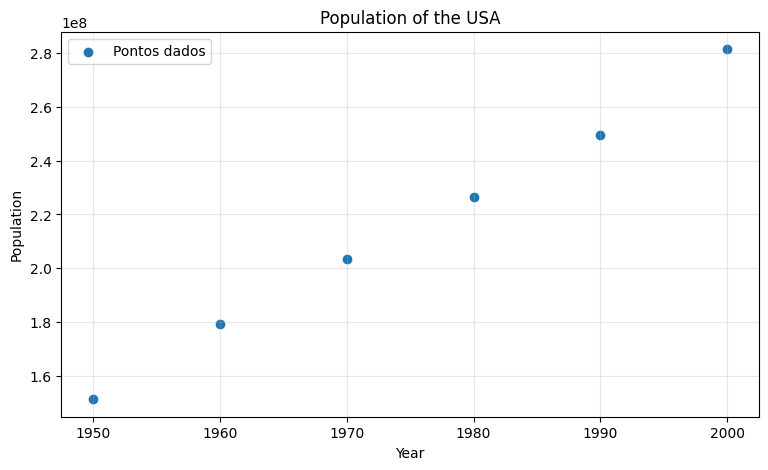

In [20]:
xs = df['Year'].values
ys = df['Population'].values*1000
plt.figure(figsize=(9,5))
plt.scatter(xs, ys, label="Pontos dados")
plt.grid(True, alpha=0.3)
plt.xlabel("Year")
plt.ylabel("Population")
plt.title("Population of the USA")
plt.legend()
plt.show()

a. Use diferenças divididas para aproximar a população nos anos de 1940, 1975 e 2020.

b. A ​​população em 1940 era de aproximadamente 132.165.000. Quão precisos você acha que são seus números para 1975 e 2020?

In [21]:
coeficientes = newton_divided_differences(xs, ys)
anos_alvo = [1940, 1975, 2020]

print("--- Estimativas da População ---")
for ano in anos_alvo:
    pop_estimada = newton_interp(ano, xs, coeficientes)
    print(f"Ano {ano}: {pop_estimada:,.0f}")

--- Estimativas da População ---
Ano 1940: 102,397,000
Ano 1975: 215,042,750
Ano 2020: 513,443,000


* **1975:** A estimativa é confiável porque 1975 está *dentro* do intervalo dos dados fornecidos (1950–2000).
* **2020:** A estimativa não é confiável porque 2020 está muito *fora* do intervalo de dados, assim como 1940.
